# 让量子电路学习一个概率分布

之前的训练从电路读取期望值。这里直接读取每种测量结果的概率，并把整组概率交给 MSE。
`loss.backward()` 会把概率误差传回电路角度。

本例严格更新两次参数，用来验证概率读出已经接通反向传播。只使用 qutai 与 Python 标准库。


In [1]:
from qutai import Tensor, nn, visualization as vis
from qutai.quantum import CNOT, RY, Circuit


## 1. 目标分布直接用列表表示

两个比特的结果依次是 `00、01、10、11`，q0 是最左侧的一位。
我们希望最终有 15% 的概率测到 `00`、85% 测到 `11`，另外两种结果的概率为 0。


In [2]:
targets = [0.15, 0.0, 0.0, 0.85]
basis = ["00", "01", "10", "11"]

vis.Table(list(zip(basis, targets)), columns=["测量结果", "目标概率"], title="要学习的概率分布")


测量结果,目标概率
00,0.15
01,0.0
10,0.0
11,0.85


## 2. 用一个角度控制两种结果的概率

RY 后接 CNOT，会准备下面的两比特状态：

$$|\psi(\theta)\rangle=\cos(\theta/2)|00\rangle+\sin(\theta/2)|11\rangle.$$

对应概率为 $P(00)=\cos^2(\theta/2)$、$P(11)=\sin^2(\theta/2)$。
通过调整角度，这个电路可以表示我们的目标分布。


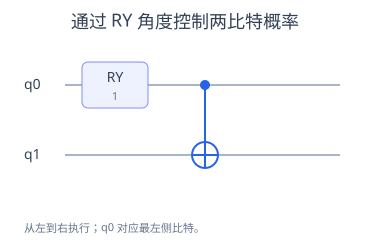

In [3]:
angle = Tensor(1.0, requires_grad=True)
circuit = Circuit(2, [RY(0, angle), CNOT(0, 1)])
optimizer = nn.SGD(circuit, learning_rate=1.0)
loss_function = nn.MSE()

vis.Circuit(circuit, title="通过 RY 角度控制两比特概率")


## 3. 训练时直接读取电路概率

`circuit.probabilities()` 返回带计算关系的 Tensor；`circuit.run().probabilities()` 返回普通数值列表。
前者用来训练，后者适合查看或采样。电路只包含普通数字角度时，电路入口也返回普通列表。


概率: [0.7701511529340699, 0.0, 0.0, 0.22984884706593015]
概率形状: (4,)
是否记录梯度: True
初始 MSE: 0.19229372624272806


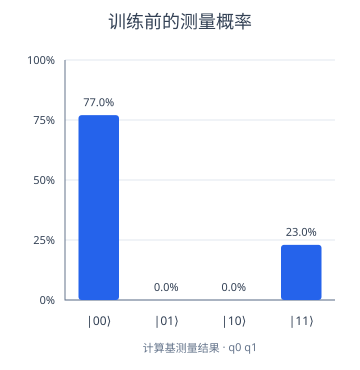

In [4]:
prediction = circuit.probabilities()
initial_loss = loss_function(prediction, targets).item()
history = [[0, angle.item(), initial_loss, prediction[3].item()]]

print("概率:", prediction.tolist())
print("概率形状:", prediction.shape)
print("是否记录梯度:", prediction.requires_grad)
print("初始 MSE:", initial_loss)

vis.Probabilities(circuit.run(), title="训练前的测量概率")


## 4. 严格更新两次参数

四个概率与四个目标值逐项比较。训练循环仍然是清梯度、计算损失、反向传播、更新参数。
概率读出默认使用伴随求导，`method="parameter-shift"` 可以切换为参数移位核对梯度。


In [5]:
for step in range(1, 3):
    optimizer.zero_grad()
    prediction = circuit.probabilities()
    loss = loss_function(prediction, targets)
    loss.backward()
    optimizer.step()

    prediction = circuit.probabilities()
    current_loss = loss_function(prediction, targets).item()
    history.append([step, angle.item(), current_loss, prediction[3].item()])
    print(f"step {step}  angle {angle.item():.6f}  MSE {current_loss:.8f}  P(11) {prediction[3].item():.6f}")

vis.Table(history, columns=["更新次数", "角度", "MSE", "P(11)"], title="两次更新的结果")


step 1  angle 1.260920  MSE 0.12623836  P(11) 0.347529
step 2  angle 1.500189  MSE 0.07421818  P(11) 0.464726


更新次数,角度,MSE,P(11)
0,1.0,0.19229372624272806,0.22984884706593015
1,1.2609196006945922,0.12623836104017963,0.34752938187356736
2,1.5001888655348143,0.07421818318552177,0.4647255960084507


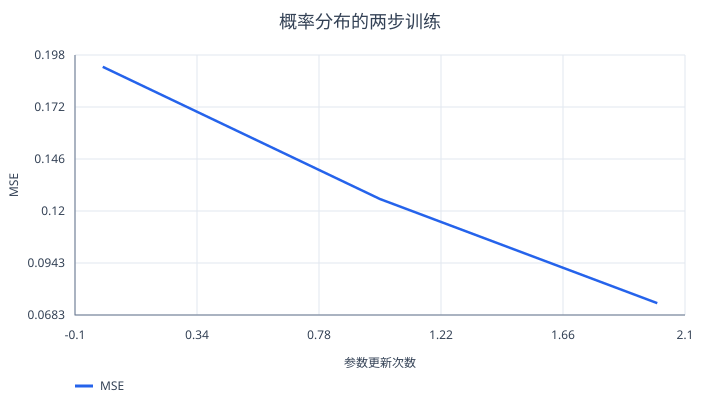

In [6]:
vis.Plot(title="概率分布的两步训练", xlabel="参数更新次数", ylabel="MSE").line(
    [row[0] for row in history], [row[2] for row in history], label="MSE"
)


## 5. 对照当前概率和目标

两步后，`11` 的概率上升、`00` 的概率下降。这个例子只验证训练流程，尚未达到目标分布。


In [7]:
vis.Table(
    [[bits, target, probability] for bits, target, probability in zip(basis, targets, prediction.tolist())],
    columns=["测量结果", "目标概率", "当前概率"],
    title="目标与当前预测",
)


测量结果,目标概率,当前概率
00,0.15,0.5352744039915494
01,0.0,0.0
10,0.0,0.0
11,0.85,0.4647255960084507


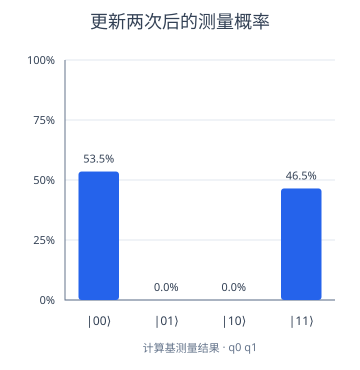

In [8]:
state = circuit.run()
vis.Probabilities(state, title="更新两次后的测量概率")


## 6. 也可以只读部分比特

`wires=0` 只返回 q0 的两个结果概率，其他比特被求和。
传入元组时保留指定顺序，例如 `(1, 0)` 的位串顺序先 q1、再 q0。
这些边缘概率同样可以接到损失函数和反向传播。


In [9]:
print("q0 的概率:", circuit.probabilities(wires=0).tolist())
print("q1、q0 顺序的概率:", circuit.probabilities(wires=(1, 0)).tolist())
print("所有概率之和:", prediction.sum().item())


q0 的概率: [0.5352744039915494, 0.4647255960084507]
q1、q0 顺序的概率: [0.5352744039915494, 0.0, 0.0, 0.4647255960084507]
所有概率之和: 1.0


概率读出没有模拟有限次测量的随机误差，这里训练的是精确理论概率。
测量坍缩和数值采样仍使用 `State.measure()`、`State.sample()` 或 `State.counts()`。

概率定义与排序参考：[PennyLane 的概率读出说明](https://docs.pennylane.ai/en/stable/code/api/pennylane.probs.html)。
